In [1]:
from google.colab import files
uploaded = files.upload()

Saving superstore.csv to superstore.csv


In [2]:
import pandas as pd

filename = next(iter(uploaded))

if filename.endswith(".csv"):
    df = pd.read_csv(filename, encoding="latin1")
elif filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    raise ValueError("Please upload a CSV or Excel file.")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert date column
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Convert numerical columns
for col in ["Sales", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep rows with valid dates and sales
df = df.dropna(subset=["Order Date", "Sales"])

# Create month column for analysis
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Rows available for visualization:", len(df))
print("Date range:",
      df["Order Date"].min().date(),
      "to",
      df["Order Date"].max().date())

display(df[["Order Date", "Sales", "Profit"]].describe())

Rows available for visualization: 9994
Date range: 2015-01-03 to 2018-12-30


,Order Date,Sales,Profit
count,9994,9994.000000,9994.000000
mean,2017-04-30 05:17:08.056834048,229.858001,28.656896
min,2015-01-03 00:00:00,0.444000,-6599.978000
25%,2016-05-23 00:00:00,17.280000,1.728750
50%,2017-06-26 00:00:00,54.490000,8.666500
75%,2018-05-14 00:00:00,209.940000,29.364000
max,2018-12-30 00:00:00,22638.480000,8399.976000
std,NaN,623.245101,234.260108


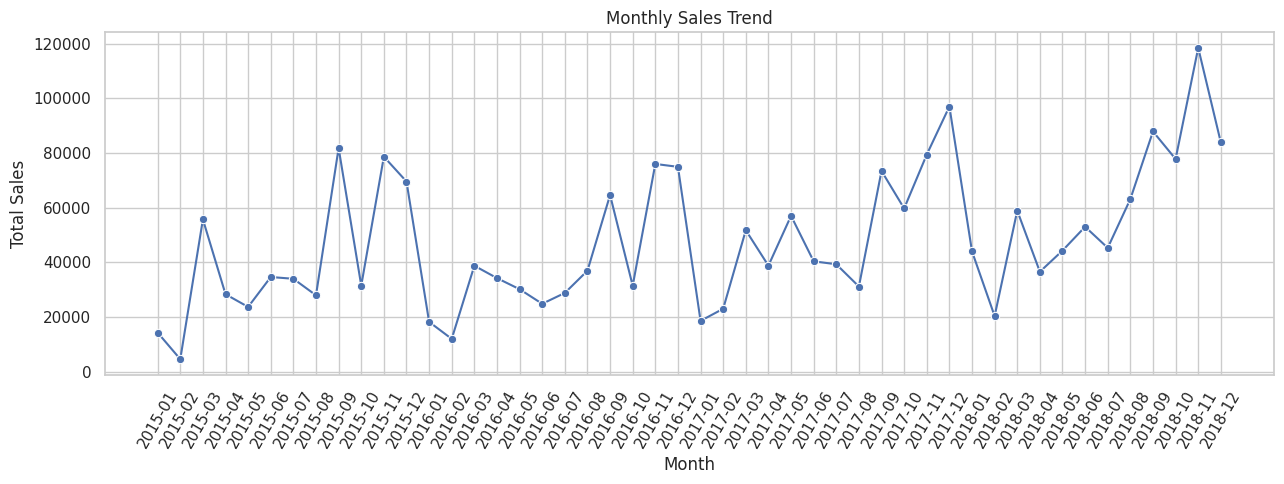

In [4]:
monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(13, 5))
sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

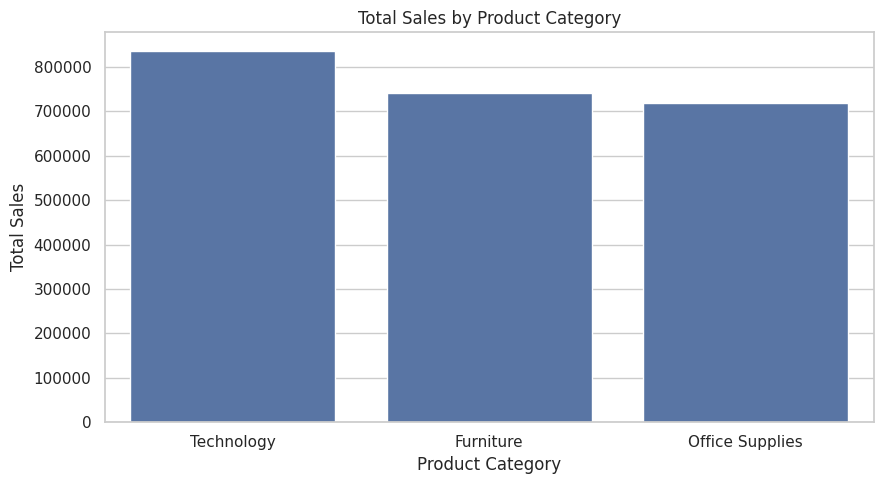

,Category,Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320


In [5]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(category_sales)

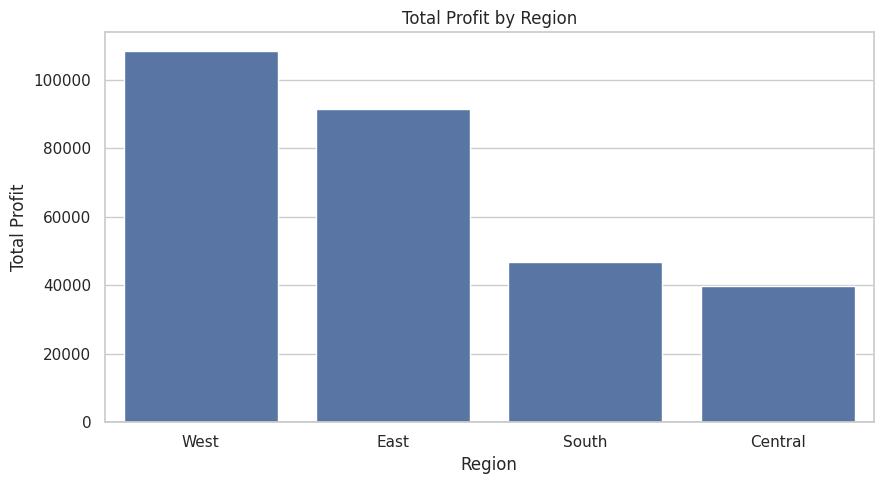

,Region,Profit
0,West,108418.4489
1,East,91522.7800
2,South,46749.4303
3,Central,39706.3625


In [6]:
region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_profit,
    x="Region",
    y="Profit"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

display(region_profit)

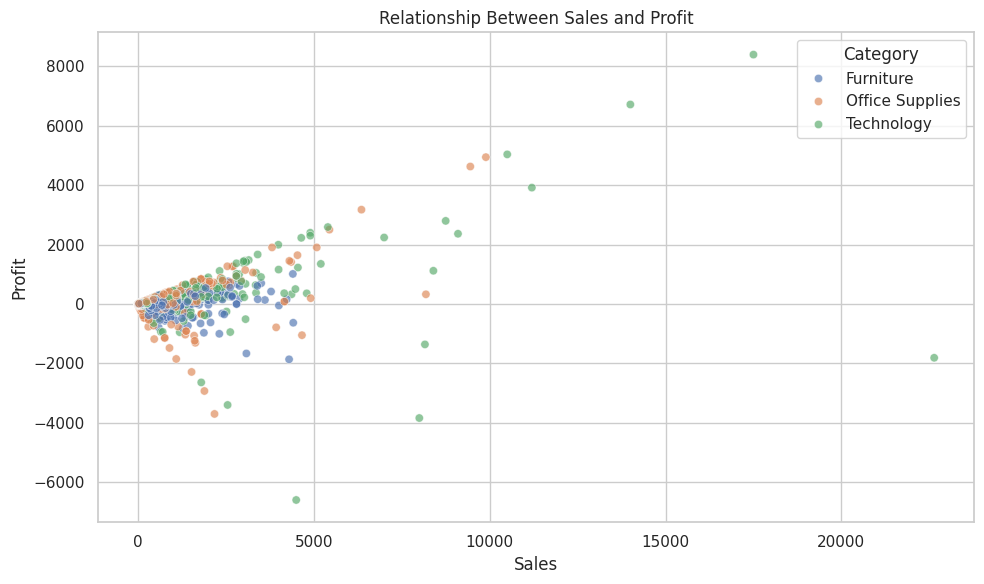

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category",
    alpha=0.65
)

plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

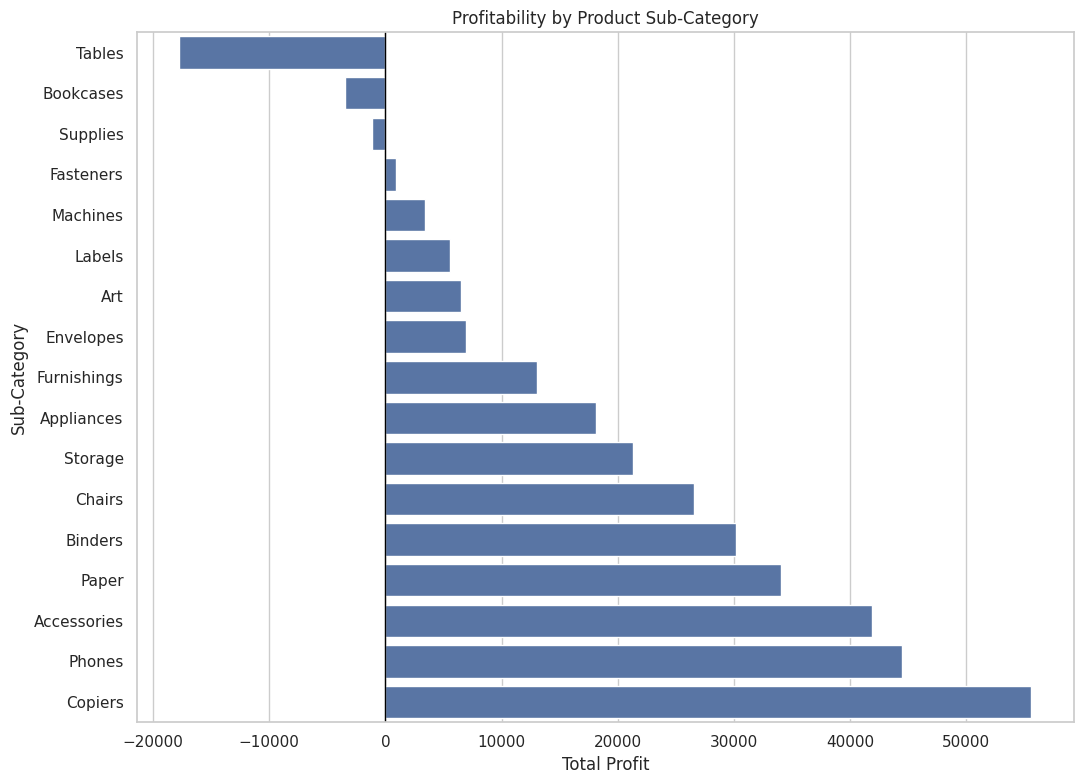

,Sub-Category,Profit
0,Tables,-17725.4811
1,Bookcases,-3472.5560
2,Supplies,-1189.0995
3,Fasteners,949.5182
4,Machines,3384.7569
5,Labels,5546.2540
6,Art,6527.7870
7,Envelopes,6964.1767
8,Furnishings,13059.1436
9,Appliances,18138.0054


In [8]:
subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=subcategory_profit,
    x="Profit",
    y="Sub-Category"
)

plt.title("Profitability by Product Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

display(subcategory_profit)

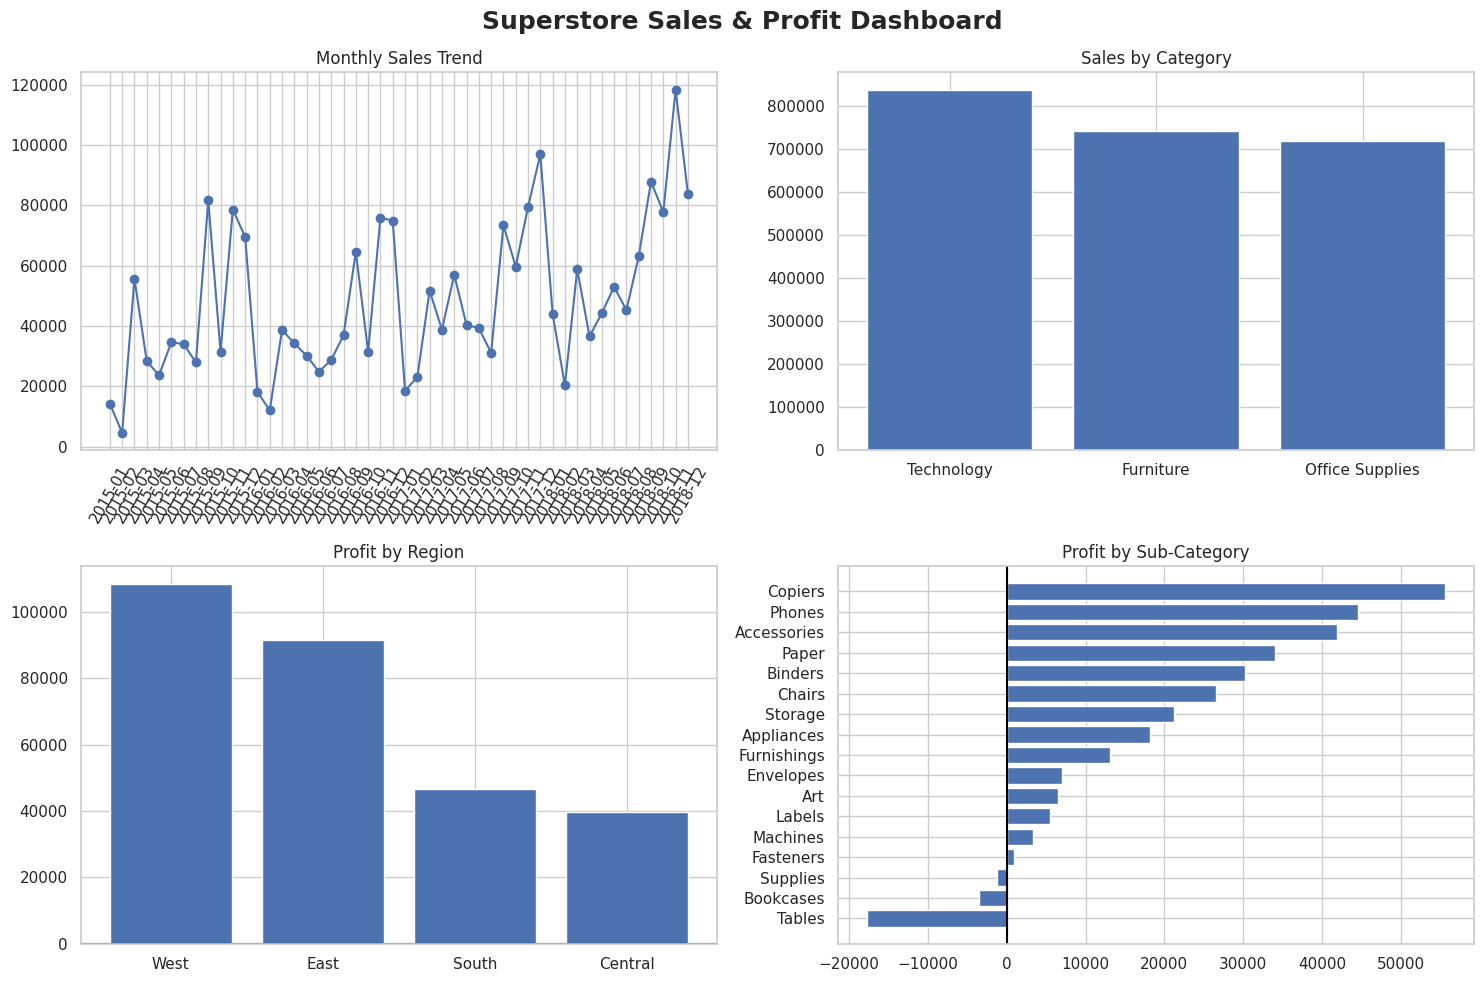

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Monthly sales
axes[0, 0].plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)
axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].tick_params(axis="x", rotation=60)

# 2. Category sales
axes[0, 1].bar(
    category_sales["Category"],
    category_sales["Sales"]
)
axes[0, 1].set_title("Sales by Category")

# 3. Regional profit
axes[1, 0].bar(
    region_profit["Region"],
    region_profit["Profit"]
)
axes[1, 0].set_title("Profit by Region")
axes[1, 0].axhline(0, color="black")

# 4. Sub-category profit
axes[1, 1].barh(
    subcategory_profit["Sub-Category"],
    subcategory_profit["Profit"]
)
axes[1, 1].set_title("Profit by Sub-Category")
axes[1, 1].axvline(0, color="black")

fig.suptitle(
    "Superstore Sales & Profit Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("superstore_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

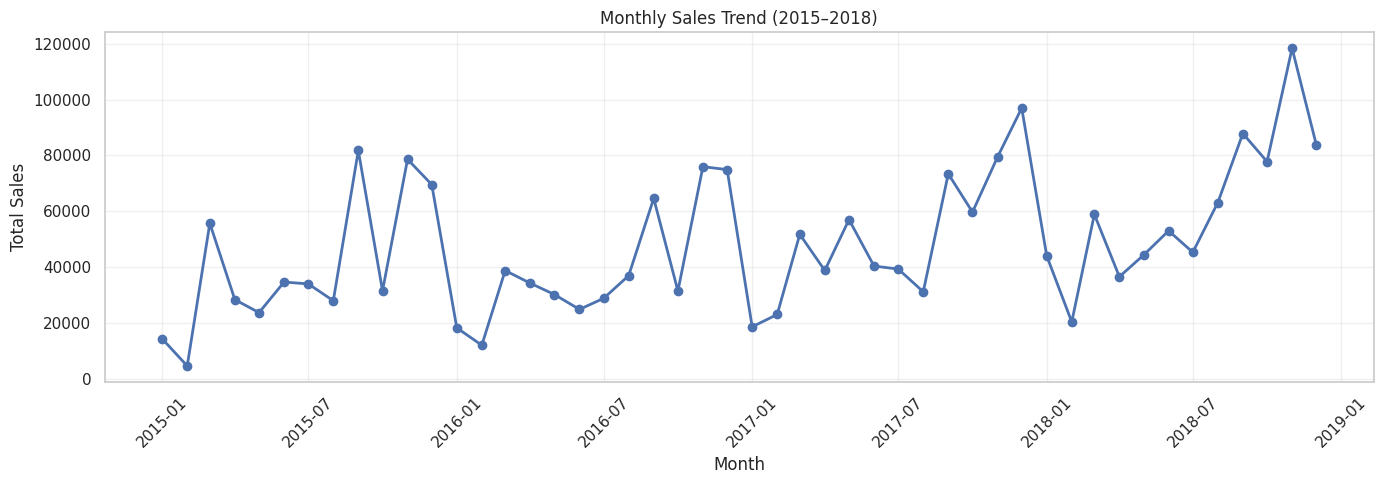

In [18]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_sales.index.to_timestamp(),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

ax.set_title("Monthly Sales Trend (2015–2018)")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

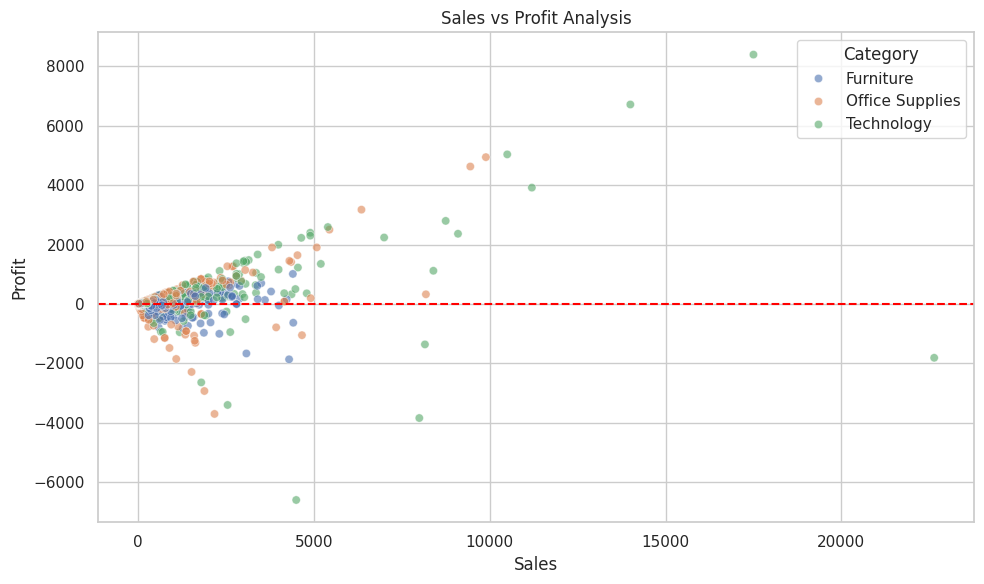

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.axhline(0, color="red", linestyle="--")
plt.title("Sales vs Profit Analysis")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

In [12]:
print("TOTAL SALES:", round(df["Sales"].sum(), 2))
print("TOTAL PROFIT:", round(df["Profit"].sum(), 2))

print("\nTOP SALES MONTH:")
print(monthly_sales.idxmax(), round(monthly_sales.max(), 2))

print("\nSALES BY CATEGORY:")
display(category_sales)

print("\nPROFIT BY REGION:")
display(region_profit)

print("\nLOWEST PROFIT SUB-CATEGORIES:")
display(subcategory_profit.head(5))

TOTAL SALES: 2297200.86
TOTAL PROFIT: 286397.02

TOP SALES MONTH:
2018-11 118447.82

SALES BY CATEGORY:


,Category,Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320



PROFIT BY REGION:


,Region,Profit
0,West,108418.4489
1,East,91522.7800
2,South,46749.4303
3,Central,39706.3625



LOWEST PROFIT SUB-CATEGORIES:


,Sub-Category,Profit
0,Tables,-17725.4811
1,Bookcases,-3472.5560
2,Supplies,-1189.0995
3,Fasteners,949.5182
4,Machines,3384.7569


In [14]:
plt.savefig(
    "Superstore_Final_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1000x600 with 0 Axes>

In [15]:
from google.colab import files
files.download("Superstore_Final_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

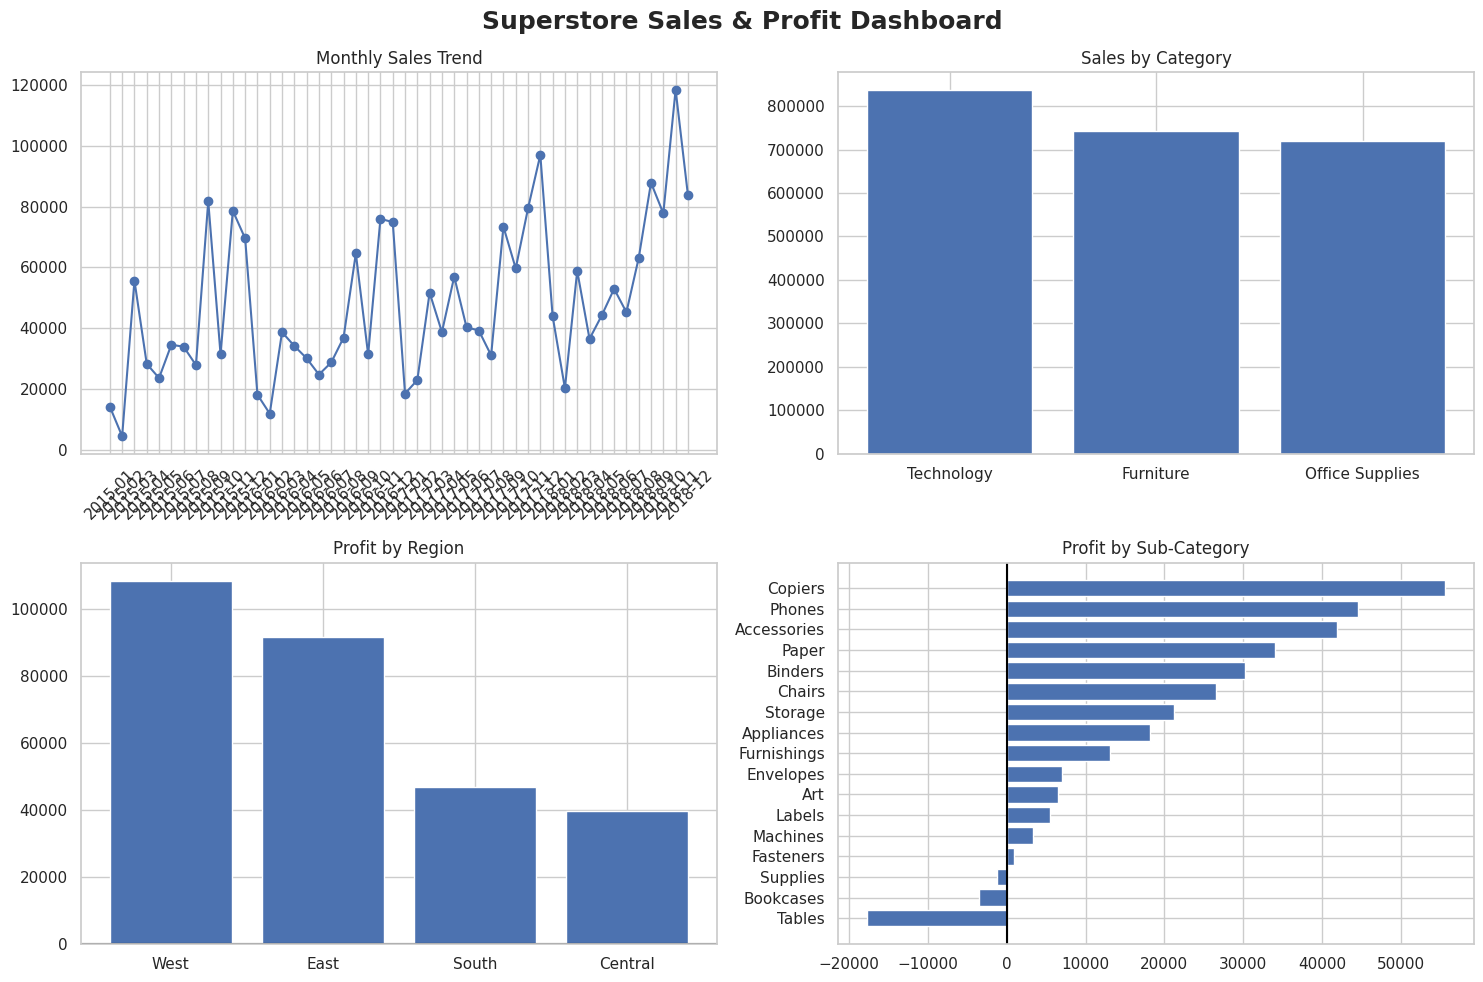

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Monthly Sales
axes[0, 0].plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)
axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].tick_params(axis="x", rotation=45)

# Sales by Category
axes[0, 1].bar(
    category_sales["Category"],
    category_sales["Sales"]
)
axes[0, 1].set_title("Sales by Category")

# Profit by Region
axes[1, 0].bar(
    region_profit["Region"],
    region_profit["Profit"]
)
axes[1, 0].set_title("Profit by Region")
axes[1, 0].axhline(0, color="black")

# Profit by Sub-Category
axes[1, 1].barh(
    subcategory_profit["Sub-Category"],
    subcategory_profit["Profit"]
)
axes[1, 1].set_title("Profit by Sub-Category")
axes[1, 1].axvline(0, color="black")

fig.suptitle(
    "Superstore Sales & Profit Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
fig.savefig(
    "Superstore_Final_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:
from google.colab import files
files.download("Superstore_Final_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
print("========== KEY BUSINESS INSIGHTS ==========")

print("\n1. TOTAL SALES:")
print(round(df["Sales"].sum(), 2))

print("\n2. TOTAL PROFIT:")
print(round(df["Profit"].sum(), 2))

print("\n3. TOP SALES MONTH:")
print(monthly_sales.idxmax(), round(monthly_sales.max(), 2))

print("\n4. SALES BY CATEGORY:")
display(category_sales)

print("\n5. PROFIT BY REGION:")
display(region_profit)

print("\n6. LOWEST PROFIT SUB-CATEGORIES:")
display(subcategory_profit.head(5))

========== KEY BUSINESS INSIGHTS ==========

1. TOTAL SALES:
2297200.86

2. TOTAL PROFIT:
286397.02

3. TOP SALES MONTH:
2018-11 118447.82

4. SALES BY CATEGORY:


,Category,Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320



5. PROFIT BY REGION:


,Region,Profit
0,West,108418.4489
1,East,91522.7800
2,South,46749.4303
3,Central,39706.3625



6. LOWEST PROFIT SUB-CATEGORIES:


,Sub-Category,Profit
0,Tables,-17725.4811
1,Bookcases,-3472.5560
2,Supplies,-1189.0995
3,Fasteners,949.5182
4,Machines,3384.7569


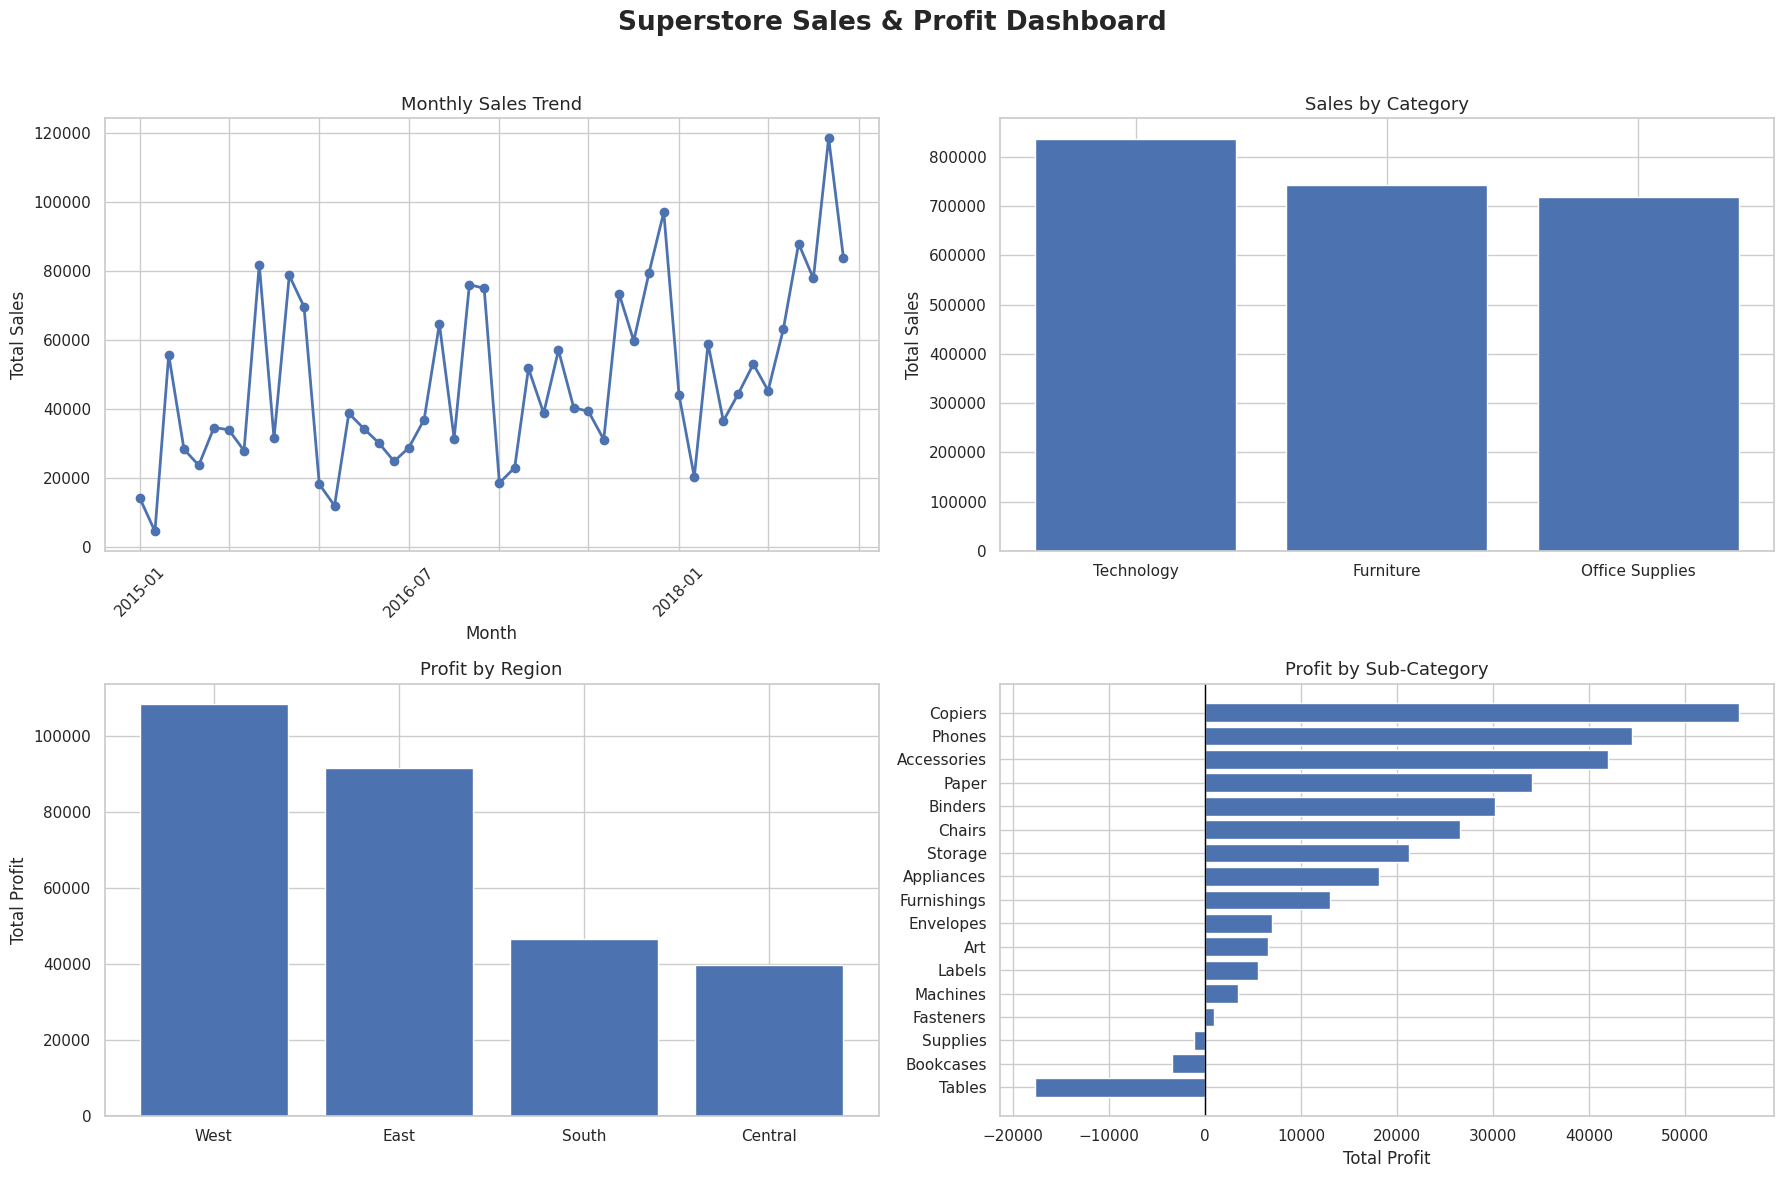

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Monthly Sales Trend
axes[0, 0].plot(
    monthly_sales.index.to_timestamp(),
    monthly_sales.values,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Monthly Sales Trend", fontsize=13)
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Total Sales")
axes[0, 0].tick_params(axis="x", labelrotation=45)

# Show only selected month labels
for i, label in enumerate(axes[0, 0].get_xticklabels()):
    label.set_visible(i % 3 == 0)

# 2. Sales by Category
axes[0, 1].bar(
    category_sales["Category"],
    category_sales["Sales"]
)
axes[0, 1].set_title("Sales by Category", fontsize=13)
axes[0, 1].set_ylabel("Total Sales")

# 3. Profit by Region
axes[1, 0].bar(
    region_profit["Region"],
    region_profit["Profit"]
)
axes[1, 0].set_title("Profit by Region", fontsize=13)
axes[1, 0].set_ylabel("Total Profit")
axes[1, 0].axhline(0, color="black", linewidth=1)

# 4. Profit by Sub-Category
axes[1, 1].barh(
    subcategory_profit["Sub-Category"],
    subcategory_profit["Profit"]
)
axes[1, 1].set_title("Profit by Sub-Category", fontsize=13)
axes[1, 1].set_xlabel("Total Profit")
axes[1, 1].axvline(0, color="black", linewidth=1)

fig.suptitle(
    "Superstore Sales & Profit Dashboard",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    "Superstore_Final_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
from google.colab import files
files.download("Superstore_Final_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>